In [ ]:
import math
import numpy as np
import pandas as pd
from tqdm import tqdm

from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit import transpile
from qiskit_aer import QasmSimulator
from qiskit.visualization import plot_histogram

from qiskit.quantum_info import Kraus
from qiskit_aer.noise import NoiseModel
from qiskit_aer.noise import QuantumError
from qiskit_aer.noise import depolarizing_error

import matplotlib.pyplot as plt
from matplotlib import rc
rc('text', usetex=True)

In [2]:
def X(qc,q,theta):
    """
    exp(-i*theta*X)
    """
    qc.rx(2*theta,q)
    
    
def Y(qc,q,theta):
    """
    exp(-i*theta*Y)
    """
    qc.ry(2*theta,q)
        
    
def Z(qc,q,theta):
    """
    exp(-i*theta*Z)
    """
    qc.rz(2*theta,q)
    
    
def XX(qc,q0,q1,theta):
    """
    exp(-i*theta*X0*X1)
    """
    qc.cx(q0,q1)
    qc.rx(2*theta,q0)
    qc.cx(q0,q1)
    
    
def YY(qc,q0,q1,theta):
    """
    exp(-i*theta*Y0*Y1)
    """
    qc.sdg(q0); qc.sdg(q1)
    qc.cx(q0,q1)
    qc.rx(2*theta,q0)
    qc.cx(q0,q1)
    qc.s(q0); qc.s(q1)
    

def ZZ(qc,q0,q1,theta):
    """
    exp(-i*theta*Z0*Z1)
    """
    qc.cx(q1,q0)
    qc.rz(2*theta,q0)
    qc.cx(q1,q0)
    
    
def XZ(qc,q0,q1,theta):
    """
    exp(-i*theta*X0*Z1)
    """
    qc.h(q0)
    qc.cx(q1,q0)
    qc.rz(2*theta,q0)
    qc.cx(q1,q0)
    qc.h(q0)
    

def ZZZ(qc,q0,q1,q2,theta):
    """
    exp(-i*theta*Z0*Z1*Z2)
    """
    qc.cx(q1,q0)
    qc.cx(q2,q0)
    qc.rz(2*theta,q0)
    qc.cx(q2,q0)
    qc.cx(q1,q0)
    

def XXX(qc,q0,q1,q2,theta):
    """
    exp(-i*theta*X0*X1*X2)
    """
    qc.cx(q0,q1)
    qc.cx(q0,q2)
    qc.rx(2*theta,q0)
    qc.cx(q0,q2)
    qc.cx(q0,q1)
    

def XYY(qc,q0,q1,q2,theta):
    """
    exp(-i*theta*X0*Y1*Y2)
    """
    qc.sdg(q1); qc.sdg(q2)
    qc.cx(q0,q1)
    qc.cx(q0,q2)
    qc.rx(2*theta,q0)
    qc.cx(q0,q2)
    qc.cx(q0,q1)
    qc.s(q1); qc.s(q2)
    
    
def XZZ(qc,q0,q1,q2,theta):
    """
    exp(-i*theta*X0*Z1*Z2)
    """
    qc.h(q0)
    qc.cx(q1,q0)
    qc.cx(q2,q0)
    qc.rz(2*theta,q0)
    qc.cx(q2,q0)
    qc.cx(q1,q0)
    qc.h(q0)
    
    
def XXZ(qc,q0,q1,q2,theta):
    """
    exp(-i*theta*X0*X1*Z2)
    """
    qc.h(q0); qc.h(q1)
    qc.cx(q1,q0)
    qc.cx(q2,q0)
    qc.rz(2*theta,q0)
    qc.cx(q2,q0)
    qc.cx(q1,q0)
    qc.h(q0); qc.h(q1)
    
    
def YYZ(qc,q0,q1,q2,theta):
    """
    exp(-i*theta*Y0*Y1*Z2)
    """
    qc.sdg(q0); qc.sdg(q1)
    qc.h(q0); qc.h(q1)
    qc.cx(q1,q0)
    qc.cx(q2,q0)
    qc.rz(2*theta,q0)
    qc.cx(q2,q0)
    qc.cx(q1,q0)
    qc.h(q0); qc.h(q1)
    qc.s(q0); qc.s(q1)
    
    
def XZZZ(qc,q0,q1,q2,q3,theta):
    """
    exp(-i*theta*X0*Z1*Z2*Z3)
    """
    qc.h(q0)
    qc.cx(q1,q0)
    qc.cx(q2,q0)
    qc.cx(q3,q0)
    qc.rz(2*theta,q0)
    qc.cx(q3,q0)
    qc.cx(q2,q0)
    qc.cx(q1,q0)
    qc.h(q0)
    
    
def XXZZ(qc,q0,q1,q2,q3,theta):
    """
    exp(-i*theta*X0*X1*Z2*Z3)
    """
    qc.h(q0); qc.h(q1)
    qc.cx(q1,q0)
    qc.cx(q2,q0)
    qc.cx(q3,q0)
    qc.rz(2*theta,q0)
    qc.cx(q3,q0)
    qc.cx(q2,q0)
    qc.cx(q1,q0)
    qc.h(q0); qc.h(q1)
    
    
def YYZZ(qc,q0,q1,q2,q3,theta):
    """
    exp(-i*theta*Y0*Y1*Z2*Z3)
    """
    qc.sdg(q0); qc.sdg(q1)
    qc.h(q0); qc.h(q1)
    qc.cx(q1,q0)
    qc.cx(q2,q0)
    qc.cx(q3,q0)
    qc.rz(2*theta,q0)
    qc.cx(q3,q0)
    qc.cx(q2,q0)
    qc.cx(q1,q0)
    qc.h(q0); qc.h(q1)
    qc.s(q0); qc.s(q1)
    
    
def XZZZZ(qc,q0,q1,q2,q3,q4,theta):
    """
    exp(-i*theta*X0*Z1*Z2*Z3*Z4)
    """
    qc.h(q0)
    qc.cx(q1,q0)
    qc.cx(q2,q0)
    qc.cx(q3,q0)
    qc.cx(q4,q0)
    qc.rz(2*theta,q0)
    qc.cx(q4,q0)
    qc.cx(q3,q0)
    qc.cx(q2,q0)
    qc.cx(q1,q0)
    qc.h(q0)

In [3]:
# Physical sites are ordered as (2,1,3,4,5,8,6,7)
# A=2; D=6,7

def H_E(qc,q,dt):
    """
    exp(-i*dt*H_E)
    """
    N = len(q)
    
    theta = -0.5625*dt
    Z(qc,q[0],theta)
    Z(qc,q[7],theta)
    
    theta = -0.375*dt
    for i in range(1,7):
        Z(qc,q[i],theta)
    
    theta = -0.1875*dt
    for i in range(0,7):
        ZZ(qc,q[i],q[i+1],theta)
    
    
def H_M(qc,q,K,dt):
    """
    exp(i*dt*K*H_M)
    """
    dt = -K*dt
    
    theta = -0.75*dt
    X(qc,q[0],theta)
    X(qc,q[7],theta)
    
    theta = 0.5625*dt
    for i in range(1,7):
        X(qc,q[i],theta)
    
    theta = -0.25*dt
    XZ(qc,q[0],q[1],theta)
    XZ(qc,q[7],q[6],theta)
    
    theta = 0.1875*dt
    XZ(qc,q[1],q[0],theta)
    XZ(qc,q[6],q[7],theta)
    for i in range(1,6):
        XZ(qc,q[i],q[i+1],theta)
        XZ(qc,q[i+1],q[i],theta)
    
    theta = 0.0625*dt
    for i in range(1,7):
        XZZ(qc,q[i],q[i-1],q[i+1],theta)

In [4]:
def evolution(qc,q,K,dt):
    """
    exp(-i*dt*(H_E - K*H_M))
    """
    H_E(qc,q,dt)
    H_M(qc,q,K,dt)

In [ ]:
def YM_fidelity(N,NA,ND,K,dt,T):
    """
    p: error probability (depolarizing channel for CX)
    """
    #noise model
    #noise_model = NoiseModel()
    #error = depolarizing_error(p,2)
    #noise_model.add_all_qubit_quantum_error(error,["cx"])
    #noisy_simulator = QasmSimulator(noise_model=noise_model)
    noisy_simulator = QasmSimulator()
    shots = 8096 # irrelevant for snapshot
    
    M= int(T/dt)
    times = np.arange(M)

    Pepr_arr = []
    Fepr_arr = []
    for time in times:

        qAAp = QuantumRegister(2*NA,"qAAp")
        qBBp = QuantumRegister(2*NB,"qBBp")
        qRRp = QuantumRegister(2*NA,"qRRp")
        cDDp = ClassicalRegister(2*ND,"cDDp")
        cRRp = ClassicalRegister(2*NA,"cRRp")
        qc = QuantumCircuit(qAAp,qBBp,qRRp,cDDp,cRRp)

        for i in range(NB):
            qc.h(qBBp[i]); qc.cx(qBBp[i],qBBp[i+NB])
        for i in range(NA):
            qc.h(qAAp[i]); qc.cx(qAAp[i],qRRp[i])
            qc.h(qAAp[i+NA]); qc.cx(qAAp[i+NA],qRRp[i+NA])

        qAB = []
        qABp= []
        for n in range(NA):
            qAB.append(qAAp[n])
            qABp.append(qAAp[n+NA])
        for n in range(NB):
            qAB.append(qBBp[n])
            qABp.append(qBBp[n+NB])
        # order of qubits (1,0,2,3,4,6,7,5)
        qev = q_arange(qAB)
        qevp= q_arange(qABp)
        for _ in range(time):
            evolution(qc,qev,K,dt)
            evolution(qc,qevp,K,-dt) # backward evolution

        # Bell measurement on DD'
        for i in range(ND):
            qc.cx(qBBp[NB-ND+i],qBBp[-ND+i]); qc.h(qBBp[NB-ND+i])
        # Bell measurement on RR'
        for i in range(NA):
            qc.cx(qRRp[i],qRRp[i+NA]); qc.h(qRRp[i])

        #qc.snapshot("1")
        for i in range(ND):
            qc.measure(qBBp[NB-ND+i],cDDp[i])
            qc.measure(qBBp[-ND+i],cDDp[i+ND])
        for i in range(NA):
            qc.measure(qRRp[i],cRRp[i])
            qc.measure(qRRp[i+NA],cRRp[i+NA])

        job = noisy_simulator.run(transpile(qc, noisy_simulator), shots=shots)
        result = job.result()
        counts = result.get_counts()
        #snapshot = result.data()["snapshots"]["statevector"]["1"][0]

        proj_counts = {}
        proj_shots = 0
        for digit,count in counts.items():
            digit = digit[::-1]
            if digit[:2*ND]=="0"*(2*ND):
                proj_shots += count
                proj_counts[digit[-2*NA:]] = count

        Pepr_arr.append(proj_shots/shots)
        Fepr_arr.append(proj_counts["0"*(2*NA)]/proj_shots)
    
    return Pepr_arr, Fepr_arr

In [7]:
N=8
NA=1
ND=2
NB=N-NA
NC=N-ND
K=2
dt=0.5
T=100
M= int(T/dt)
times = np.arange(M)

def q_arange(q):
    return [q[1],q[0],q[2],q[3],q[4],q[6],q[7],q[5]]

Pepr,Fepr = YM_fidelity(N,NA,ND,K,dt,T)

In [8]:
def F_haar(NA,ND):
    dA = 2**NA
    dD = 2**ND
    return 1/(1+(dA/dD)**2-dD**(-2))

def P_haar(NA,ND):
    dA = 2**NA
    dD = 2**ND
    return dA**(-2) + dD**(-2)-(dA*dD)**(-2)

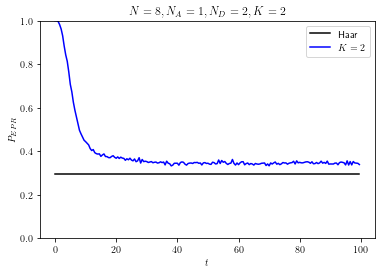

In [13]:
plt.plot(dt*times,P_haar(NA,ND)+0*dt*times,"-",color="black",label="Haar")
plt.plot(dt*times,Pepr,"b-",label=r"$K=2$")

plt.xlabel("$t$")
plt.ylabel(r"$P_{EPR}$")
plt.ylim([0,1])
plt.title(f"$N={N}, N_A={NA}, N_D={ND}, K={2}$") #dt={dt}
plt.legend()
plt.show()

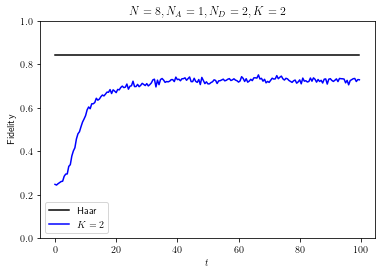

In [14]:
plt.plot(dt*times,F_haar(NA,ND)+0*dt*times,"-",color="black",label="Haar")
plt.plot(dt*times,Fepr,"b-",label=r"$K=2$")

plt.xlabel("$t$")
plt.ylabel(r"Fidelity")
plt.ylim([0,1])
plt.title(f"$N={N}, N_A={NA}, N_D={ND}, K={2}$") #dt={dt}
plt.legend()
plt.show()